# Bremsstrahlung relativista y comptonización de un plasma
Notebook autocontenido. Ejecutar **Run All**; editar la celda de parámetros y volver a ejecutar desde ella. Las tres figuras muestran **1–100 keV**, aunque el transporte sigue fotones fuera de esa banda.

Modelo: esfera homogénea de hidrógeno totalmente ionizado, electrones isotrópicos y temperatura impuesta. **El tamaño introducido es el radio**, en km. La densidad fija tanto la emisión como la profundidad óptica radial $\tau_T=n_e\sigma_T R$. Se necesitan densidad, distancia y luminosidad incidente: temperatura y tamaño solos no fijan un flujo absoluto.

Para el haz, las salidas se integran sobre todos los ángulos y se representa $\overline F_E=L_E/(4\pi d^2)$: un flujo equivalente promediado angularmente, **no el espectro hacia una línea de visión concreta**. El haz es paralelo e ilumina uniformemente el disco de la esfera; su luminosidad es la potencia que intercepta ese disco.

In [7]:
# Si faltan dependencias, descomentar y ejecutar:
# %pip install numpy scipy matplotlib ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": .2})

## Física y unidades
La distribución térmica es Maxwell–Jüttner en energía cinética $T_e$:
$$f(T_e)=\frac{\gamma\sqrt{\gamma^2-1}\exp(-T_e/kT)}{kT\,e^{1/\theta}K_2(1/\theta)},\quad \gamma=1+T_e/(m_ec^2),\quad\theta=kT/(m_ec^2).$$
Se usa la función de Bessel escalada para evitar desbordamientos. Puede sustituirse por una distribución de energía personalizada, normalizada numéricamente; $kT$ pasa entonces a fijar la malla, no la forma de esa distribución.

La producción de fotones de bremsstrahlung electrón–ión se integra como
$$\dot N_E=Vn_en_i\int_E^\infty f(T_e)v(T_e)\frac{d\sigma}{dE}\,dT_e,\qquad n_i=n_e.$$
Se implementa Bethe–Heitler con corrección de Elwert. Referencia de la sección eficaz: [Chluba, Ravenni & Bolliet (2020), ecuaciones 1, 7 y 9](https://arxiv.org/html/1911.08861). Es una aproximación, no el cálculo completo de Elwert–Haug; se restringe a H y $1\le kT\le300$ keV.

Compton: transporte Monte Carlo espacial hasta el escape, transformaciones de Lorentz y sección eficaz diferencial de Klein–Nishina en el reposo del electrón. La selección de colisiones incluye el factor relativo $1-\boldsymbol\beta\cdot\hat n$. Véase [la documentación de física de Geant4](https://geant4.web.cern.ch/documentation/dev/prm_html/PhysicsReferenceManual/electromagnetic/gamma_incident/compton/compton.html). Se permite tanto ganancia como pérdida energética y dispersión múltiple. La temperatura permanece fija: la energía intercambiada procede de un reservorio térmico implícito.

In [8]:
"""Plasma de H ionizado: BH-Elwert y transporte Compton relativista. CGS/keV."""
import numpy as np
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.special import kve
MEC2=510.99895
SIGMA_T=6.6524587321e-25
C=2.99792458e10
ALPHA=1/137.035999084
KEV=1.602176634e-9
KPC=3.085677581491367e21

def mj_pdf(T, kT):
    """Densidad normalizada por keV de energía cinética."""
    T=np.asarray(T); g=1+T/MEC2; p=np.sqrt((T/MEC2)*(2+T/MEC2))
    return g*p*np.exp(-T/kT)/(kT*kve(2,MEC2/kT))

def electron_grid(kT, custom=None):
    if not 1 <= kT <= 300: raise ValueError('kT debe estar entre 1 y 300 keV.')
    t=np.geomspace(kT*1e-8, max(60*kT,1000), 8000)
    f=mj_pdf(t,kT) if custom is None else np.asarray(custom(t),float)
    if f.shape!=t.shape or not np.all(np.isfinite(f)) or np.any(f<0):
        raise ValueError('La distribución debe ser finita, no negativa y del mismo tamaño que T.')
    norm=trapezoid(f,t)
    if norm<=0: raise ValueError('Distribución vacía en la malla electrónica.')
    f=f/norm
    cdf=cumulative_trapezoid(f,t,initial=0); cdf/=cdf[-1]
    return t,f,cdf

def bh_elwert(E,T):
    """d sigma/dE [cm²/keV], Z=1. Chluba+2020 ecs. 1,7,9."""
    T,E=np.broadcast_arrays(np.asarray(T,dtype=np.longdouble),np.asarray(E,dtype=np.longdouble))
    out=np.zeros(T.shape,dtype=np.longdouble); ok=T>E
    a=T[ok]/MEC2; w=E[ok]/MEC2; b=a-w
    g1=1+a; g2=1+b; p1=np.sqrt(a*(a+2)); p2=np.sqrt(b*(b+2))
    l1=np.arcsinh(p1); l2=np.arcsinh(p2)
    L=np.log((a+b+a*b+p1*p2)/w)
    g=(p1*p2/4-3*g1*g2/8*(p1/p2+p2/p1)+g1*g2*L
       +3*w*L/8*((1+g1*g2/p1**2)*l1/p1-(1+g1*g2/p2**2)*l2/p2
       +w*(1+(g1*g2+g1**2*g2**2)/(p1*p2)**2))
       +3/8*(g2*p2/p1**2*l1+g1*p1/p2**2*l2-2*l1*l2))*np.sqrt(3)/np.pi
    eta1=ALPHA*g1/p1; eta2=ALPHA*g2/p2
    elwert=eta2/eta1*np.expm1(-2*np.pi*eta1)/np.expm1(-2*np.pi*eta2)
    if np.any(g< -1e-8): raise ArithmeticError('Cancelación numérica en BH.')
    out[ok]=2*ALPHA/np.sqrt(3)*SIGMA_T/(p1*p1*w)*np.maximum(g,0)*elwert/MEC2
    return np.asarray(out,float)

def brems(E,kT,ne,radius_km,custom=None,nquad=1500):
    """Luminosidad espectral de fotones [s^-1 keV^-1], n_i=n_e."""
    grid,f,_=electron_grid(kT,custom)
    result=[]
    for e in np.asarray(E):
        if e>=grid[-1]: result.append(0.); continue
        # Malla desplazada: resuelve el umbral cinemático T=E.
        t=e+np.geomspace(max(1e-7,e*1e-8),grid[-1]-e,nquad)
        pdf=mj_pdf(t,kT) if custom is None else np.interp(t,grid,f,left=0,right=0)
        p=np.sqrt((t/MEC2)*(2+t/MEC2)); beta=p/(1+t/MEC2)
        result.append(trapezoid(pdf*C*beta*bh_elwert(e,t),t))
    return np.array(result)*ne**2*(4*np.pi/3)*(radius_km*1e5)**3

def isotropic(n,rng):
    v=rng.normal(size=(n,3)); return v/np.linalg.norm(v,axis=1)[:,None]

def boost(E,n,b):
    """Transforma fotón al marco que se mueve con velocidad b*c."""
    b2=np.sum(b*b,axis=1); gamma=1/np.sqrt(1-b2); dot=np.sum(b*n,axis=1)
    energy=gamma*E*(1-dot)
    coeff=np.divide(gamma-1,b2,out=np.zeros_like(b2),where=b2>0)*dot-gamma
    direction=(n+coeff[:,None]*b)/(gamma*(1-dot))[:,None]
    return energy,direction

def kn_ratio(x):
    x=np.asarray(x); y=np.maximum(x,1e-3); l=np.log1p(2*y)
    value=.75*((1+y)/y**3*(2*y*(1+y)/(1+2*y)-l)+l/(2*y)-(1+3*y)/(1+2*y)**2)
    return np.where(x<1e-3,1-2*x+5.2*x*x,value)

def scatter(E,n,b,rng):
    er,nr=boost(E,n,b); x=er/MEC2
    mu=np.empty(len(E)); pending=np.arange(len(E))
    while len(pending):
        trial=rng.uniform(-1,1,len(pending)); r=1/(1+x[pending]*(1-trial))
        accept=rng.random(len(pending)) < .5*r*r*(r+1/r-(1-trial*trial))
        mu[pending[accept]]=trial[accept]; pending=pending[~accept]
    axis=np.zeros_like(nr); axis[:,2]=1; axis[np.abs(nr[:,2])>.9]=[1,0,0]
    u=np.cross(nr,axis); u/=np.linalg.norm(u,axis=1)[:,None]; v=np.cross(nr,u)
    phi=rng.uniform(0,2*np.pi,len(E))
    nr2=mu[:,None]*nr+np.sqrt(1-mu*mu)[:,None]*(np.cos(phi)[:,None]*u+np.sin(phi)[:,None]*v)
    return boost(er/(1+x*(1-mu)),nr2,-b)

def transport(E,kT,tau,rng,source='beam',custom=None):
    """Esfera de radio unidad. Colisiones nulas con cota 2*n_e*sigma_T.
    Salida integrada sobre todas las direcciones; tau=n_e*sigma_T*R.
    """
    if not 0<=tau<=3: raise ValueError('Usar 0 <= tau radial <= 3.')
    E=np.array(E,float,copy=True); nphot=len(E); counts=np.zeros(nphot,int)
    if tau==0: return E,counts
    t,_,cdf=electron_grid(kT,custom)
    if source=='beam':
        r=np.sqrt(rng.random(nphot)); phi=rng.uniform(0,2*np.pi,nphot)
        pos=np.column_stack((r*np.cos(phi),r*np.sin(phi),-np.sqrt(1-r*r)))
        direction=np.tile([0.,0.,1.],(nphot,1))
    elif source=='internal':
        pos=isotropic(nphot,rng)*rng.random(nphot)[:,None]**(1/3)
        direction=isotropic(nphot,rng)
    else: raise ValueError('source: beam o internal')
    active=np.arange(nphot)
    for _ in range(20000):
        if not len(active): return E,counts
        dot=np.sum(pos[active]*direction[active],axis=1)
        edge=-dot+np.sqrt(np.maximum(0,dot*dot+1-np.sum(pos[active]**2,axis=1)))
        step=rng.exponential(1/(2*tau),len(active))
        active=active[step<edge]; step=step[step<edge]
        pos[active]+=step[:,None]*direction[active]
        g=1+np.interp(rng.random(len(active)),cdf,t)/MEC2
        b=isotropic(len(active),rng)*np.sqrt(1-1/g**2)[:,None]
        relative=1-np.sum(b*direction[active],axis=1)
        x=g*E[active]*relative/MEC2
        accepted=rng.random(len(active)) < relative*kn_ratio(x)/2
        ids=active[accepted]
        E[ids],direction[ids]=scatter(E[ids],direction[ids],b[accepted],rng)
        counts[ids]+=1
    raise RuntimeError('Transporte sin completar; no se devuelve un espectro truncado.')

def sample_spectrum(grid,photons,n,rng):
    cdf=cumulative_trapezoid(photons,grid,initial=0); total=cdf[-1]
    if total<=0: raise ValueError('Espectro semilla vacío.')
    return np.interp(rng.random(n)*total,cdf,grid),total

def histogram_flux(E,total_rate,bins,distance_kpc,n_original):
    """Flujo energético bin-promediado, con error Monte Carlo [erg/cm²/s/keV]."""
    weights=E*KEV*total_rate/n_original/(4*np.pi*(distance_kpc*KPC)**2)
    flux=np.histogram(E,bins,weights=weights)[0]/np.diff(bins)
    error=np.sqrt(np.histogram(E,bins,weights=weights**2)[0])/np.diff(bins)
    return flux,error


## Parámetros editables
El índice es **de fotones**: $d\dot N/dE=A E^{-\Gamma}$. `L_haz` se integra únicamente entre `Emin_haz` y `Emax_haz`. `N_fotones` controla el ruido y el tiempo de cálculo.

In [9]:
kT = 50.0                 # keV, 1–300
radio_km = 100.0          # radio de la esfera
ne = 1e17                # electrones/cm³ (protones: misma densidad)
distancia_kpc = 5.0
Emin_haz = 0.2            # keV
Emax_haz = 20.0           # keV
Gamma = 2.0              # índice de fotones
L_haz = 1e35              # erg/s interceptados por la esfera
N_fotones = 60000         # por componente; subir para reducir ruido
semilla = 2026
comptonizar_brems = True # False: suma brems intrínseco + haz emergente
Emin_brems_semilla = 0.05 # corte inferior físico/numérico explícito, keV
Emax_brems_semilla = 3000.0
custom_electrons = None   # None = Maxwell–Jüttner
# Ejemplo alternativo isotrópico (T en keV):
# custom_electrons = lambda T: .9*mj_pdf(T,kT) + .1*mj_pdf(T,3*kT)
# La cola debe estar contenida en max(60*kT,1000) keV; amplíe electron_grid si hace falta.


tau_T radial = 0.6652; fotones del haz dispersados = 56.6%
Haz: energía de salida/entrada (todas las energías) = 1.502
Haz: fracción numérica fuera de 1–100 keV = 71.8%


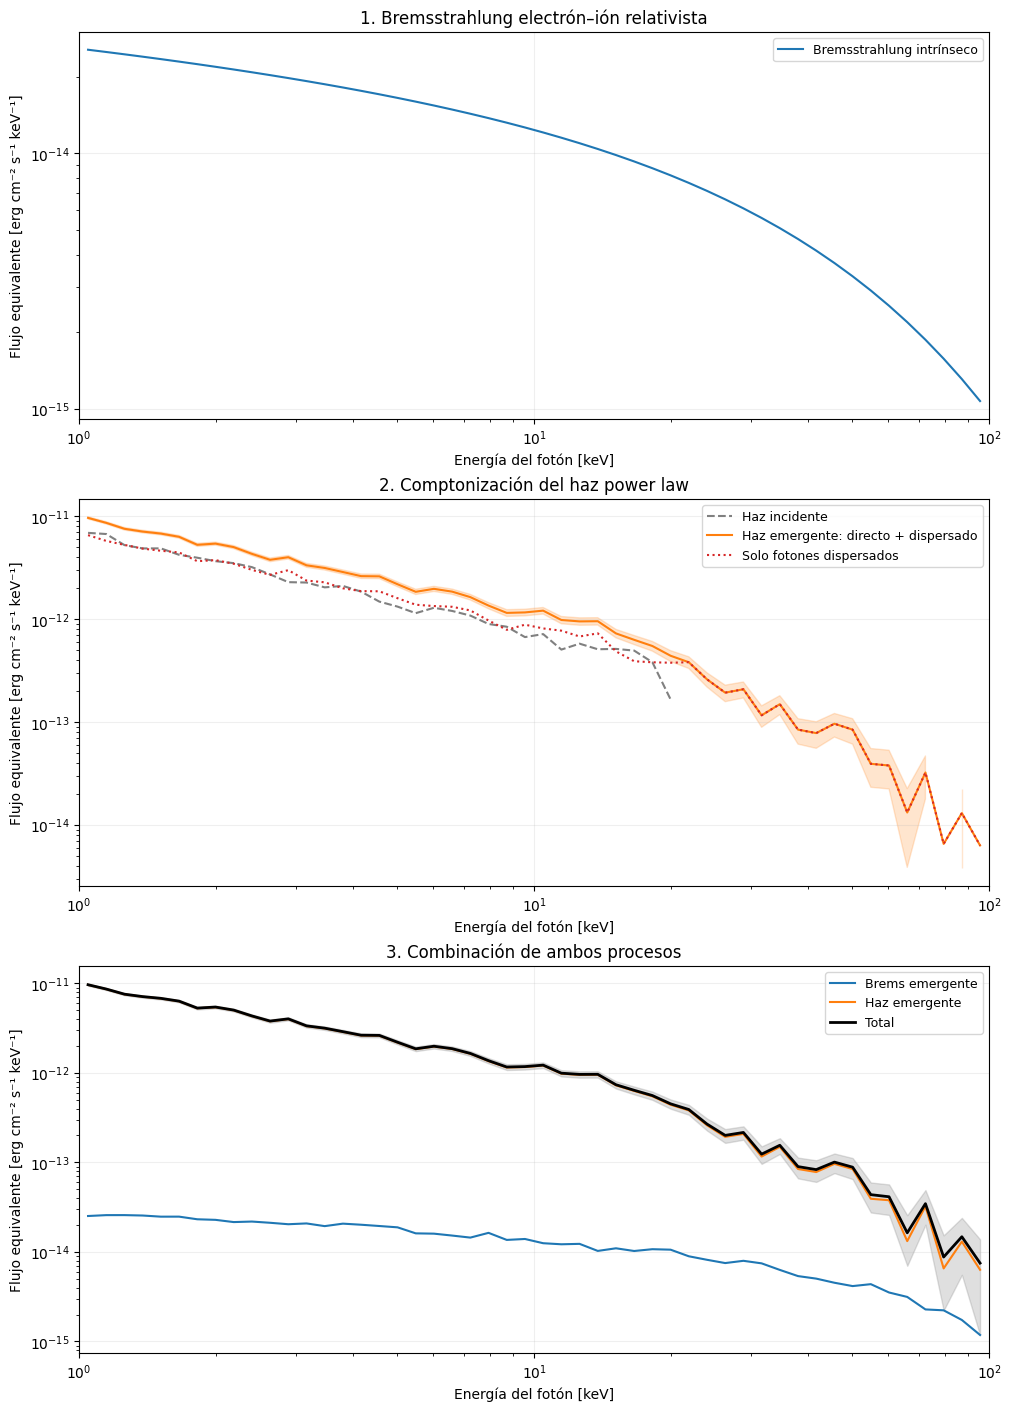

In [10]:
def calcular(kT, radio_km, ne, distancia_kpc, Emin_haz, Emax_haz,
             Gamma, L_haz, N_fotones, semilla, comptonizar_brems,
             Emin_brems_semilla, Emax_brems_semilla, custom_electrons=None):
    vals=[kT,radio_km,ne,distancia_kpc,Emin_haz,Emax_haz,Gamma,L_haz,
          Emin_brems_semilla,Emax_brems_semilla]
    if not np.all(np.isfinite(vals)): raise ValueError('Parámetros no finitos.')
    if min(radio_km,distancia_kpc,Emin_haz,Emin_brems_semilla)<=0 or ne<0 or L_haz<=0:
        raise ValueError('Radio, distancia, energías y L_haz positivos; ne >= 0.')
    if Emax_haz<=Emin_haz or Emax_brems_semilla<=Emin_brems_semilla:
        raise ValueError('Cada máximo energético debe superar su mínimo.')
    if int(N_fotones)!=N_fotones or N_fotones<1000: raise ValueError('N_fotones entero >= 1000.')
    N_fotones=int(N_fotones)
    electron_grid(kT,custom_electrons)
    tau=ne*SIGMA_T*radio_km*1e5
    if tau>3: raise ValueError(f'tau={tau:.2g}>3: reducir densidad o radio para este notebook.')
    rng=np.random.default_rng(semilla)
    bins=np.geomspace(1,100,51); energy=np.sqrt(bins[:-1]*bins[1:])
    distance_factor=4*np.pi*(distancia_kpc*KPC)**2
    bgrid=np.geomspace(Emin_brems_semilla,Emax_brems_semilla,700)
    bn=brems(bgrid,kT,ne,radio_km,custom_electrons)
    intrinsic=brems(energy,kT,ne,radio_km,custom_electrons)*energy*KEV/distance_factor
    hgrid=np.geomspace(Emin_haz,Emax_haz,4000)
    shape=np.exp(-Gamma*np.log(hgrid/np.sqrt(Emin_haz*Emax_haz)))
    hn=shape*L_haz/(KEV*trapezoid(hgrid*shape,hgrid))
    initial,rate=sample_spectrum(hgrid,hn,N_fotones,rng)
    escaped,counts=transport(initial,kT,tau,rng,custom=custom_electrons)
    hf,he=histogram_flux(escaped,rate,bins,distancia_kpc,N_fotones)
    hs,_=histogram_flux(escaped[counts>0],rate,bins,distancia_kpc,N_fotones)
    hi,_=histogram_flux(initial,rate,bins,distancia_kpc,N_fotones)
    bf=intrinsic.copy(); be=np.zeros_like(bf)
    if comptonizar_brems and ne>0:
        bi,br=sample_spectrum(bgrid,bn,N_fotones,rng)
        bo,bc=transport(bi,kT,tau,rng,source='internal',custom=custom_electrons)
        bf,be=histogram_flux(bo,br,bins,distancia_kpc,N_fotones)
    print(f'tau_T radial = {tau:.4g}; fotones del haz dispersados = {np.mean(counts>0):.1%}')
    print(f'Haz: energía de salida/entrada (todas las energías) = {escaped.sum()/initial.sum():.4g}')
    print(f'Haz: fracción numérica fuera de 1–100 keV = {np.mean((escaped<1)|(escaped>100)):.1%}')
    fig,axes=plt.subplots(3,1,figsize=(10,14),constrained_layout=True)
    def line(ax,y,label,**kw):
        ax.loglog(energy,np.where(y>0,y,np.nan),label=label,**kw)
    line(axes[0],intrinsic,'Bremsstrahlung intrínseco',color='tab:blue')
    axes[0].set_title('1. Bremsstrahlung electrón–ión relativista')
    line(axes[1],hi,'Haz incidente',ls='--',color='gray')
    line(axes[1],hf,'Haz emergente: directo + dispersado',color='tab:orange')
    line(axes[1],hs,'Solo fotones dispersados',ls=':',color='tab:red')
    axes[1].fill_between(energy,np.where(hf>he,hf-he,np.nan),hf+he,alpha=.2,color='tab:orange')
    axes[1].set_title('2. Comptonización del haz power law')
    line(axes[2],bf,'Brems emergente' if comptonizar_brems else 'Brems intrínseco')
    line(axes[2],hf,'Haz emergente')
    line(axes[2],bf+hf,'Total',color='black',lw=2)
    err=np.hypot(be,he)
    axes[2].fill_between(energy,np.where(bf+hf>err,bf+hf-err,np.nan),bf+hf+err,color='gray',alpha=.25)
    axes[2].set_title('3. Combinación de ambos procesos')
    for ax in axes:
        ax.set(xlim=(1,100),xlabel='Energía del fotón [keV]',ylabel='Flujo equivalente [erg cm⁻² s⁻¹ keV⁻¹]')
        ax.legend(fontsize=9)
    plt.show()
    return dict(E_keV=energy,brems_intrinseco=intrinsic,brems_emergente=bf,
                haz_emergente=hf,total=bf+hf,error_MC=err,bins=bins,fig=fig)

parametros = dict(kT=kT,radio_km=radio_km,ne=ne,distancia_kpc=distancia_kpc,
    Emin_haz=Emin_haz,Emax_haz=Emax_haz,Gamma=Gamma,L_haz=L_haz,
    N_fotones=N_fotones,semilla=semilla,comptonizar_brems=comptonizar_brems,
    Emin_brems_semilla=Emin_brems_semilla,Emax_brems_semilla=Emax_brems_semilla,
    custom_electrons=custom_electrons)
resultado = calcular(**parametros)

## Controles interactivos opcionales
El botón recalcula con los valores del panel y conserva el resto de `parametros`. Cambiar la distribución personalizada requiere editar la celda anterior. Los resultados del panel se guardan en `resultado`.

In [11]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    controles = {
        'kT': widgets.FloatText(value=kT,description='kT [keV]'),
        'radio_km': widgets.FloatText(value=radio_km,description='Radio [km]'),
        'ne': widgets.FloatText(value=ne,description='ne [cm⁻³]'),
        'distancia_kpc': widgets.FloatText(value=distancia_kpc,description='d [kpc]'),
        'Emin_haz': widgets.FloatText(value=Emin_haz,description='Emin [keV]'),
        'Emax_haz': widgets.FloatText(value=Emax_haz,description='Emax [keV]'),
        'Gamma': widgets.FloatText(value=Gamma,description='Γ fotones'),
        'L_haz': widgets.FloatText(value=L_haz,description='L [erg/s]'),
        'N_fotones': widgets.IntText(value=N_fotones,description='Fotones'),
        'comptonizar_brems': widgets.Checkbox(value=True,description='Comptonizar brems')}
    boton=widgets.Button(description='Calcular espectros',button_style='primary')
    salida=widgets.Output()
    def actualizar(_):
        global resultado
        with salida:
            clear_output(wait=True)
            try:
                resultado=calcular(**(parametros | {key:w.value for key,w in controles.items()}))
            except (ValueError,ArithmeticError,RuntimeError) as exc:
                print(str(exc))
    boton.on_click(actualizar)
    display(widgets.VBox(list(controles.values())+[boton,salida]))
except ImportError:
    print('Panel no instalado: edite la celda de parámetros o instale ipywidgets.')

## Exportar los resultados
Se exporta el último cálculo (también si procede del panel).

In [12]:
salida_dir=Path('resultados_plasma'); salida_dir.mkdir(exist_ok=True)
columnas=['E_keV','brems_intrinseco','brems_emergente','haz_emergente','total','error_MC']
np.savetxt(salida_dir/'espectros.csv',np.column_stack([resultado[k] for k in columnas]),
           delimiter=',',header=','.join(columnas),comments='')
resultado['fig'].savefig(salida_dir/'espectros.png',dpi=160)
print('Resultados en:',salida_dir.resolve())

Resultados en: /Users/pedro.blay/Downloads/bexrb/notebooks/resultados_plasma


## Alcance y convergencia
- El componente brems incluye **electrón–ión**; no electrón–electrón, que puede ser relevante al aumentar kT. No se calcula equilibrio térmico, pares, absorción libre–libre, fotoabsorción, líneas, campos magnéticos ni relatividad gravitatoria. El plasma se supone diluido, no degenerado y con baja ocupación fotónica (sin Compton inducido).
- La primera figura es producción intrínseca, antes de transporte. En la tercera, los fotones internos se transportan si está activada la opción. El haz emergente incluye transmisión directa; se muestra además su componente dispersada. No se suma de nuevo la semilla a su espectro emergente.
- El espectro de semillas brems tiene un **corte inferior explícito**: su número de fotones diverge al aproximarse a energía cero sin absorción. Reducir `Emin_brems_semilla` y aumentar `Emax_brems_semilla` hasta estabilizar la banda de interés. En un plasma real habría que calcular la autoabsorción para justificar ese corte.
- La banda sombreada es una estimación del error de muestreo por bin, no incertidumbre física. Los bins vacíos se omiten en escala logarítmica. Aumentar `N_fotones` por un factor 4 reduce aproximadamente el ruido a la mitad. Comparar semillas independientes y duplicar la cuadratura de brems para comprobar convergencia.
- Se limita la profundidad óptica radial a 3 por coste de ejecución. La conservación relevante para Compton es la del **número de fotones**, no su energía por separado: el reservorio de electrones puede suministrar o absorber energía.
- El flujo del haz es un promedio angular; para una observación de un haz anisótropo se necesita seleccionar direcciones de escape y normalizar por su ángulo sólido.